In [1]:
# # 01 Data Analysis: UCI Student Performance
# Goal: load the raw data and understand every feature.
# Target: `G3` (final grade, 0 to 20). Pass mark: `G3 >= 10`.

In [2]:
import pandas as pd
from aislca.data.ingestion import load_student_data

pd.set_option("display.max_columns", None)  # show all columns

In [3]:
df_mat = load_student_data("mat")
df_por = load_student_data("por")
print("Math shape:", df_mat.shape)
print("Portuguese shape:", df_por.shape)

Math shape: (395, 33)
Portuguese shape: (649, 33)


In [4]:
df_mat.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [5]:
df_mat.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [6]:
df_mat.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [7]:
print(df_mat["G3"].describe())
print("Students with G3 >= 10 (pass):", (df_mat["G3"] >= 10).mean().round(3))

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64
Students with G3 >= 10 (pass): 0.671


In [8]:
## Data cleaning checks
# Missing values, duplicates, types, outliers and suspicious grades.


In [9]:
from aislca.data.cleaning import missing_report, find_outliers_iqr, OUTLIER_COLUMNS

print("Missing values:\n", missing_report(df_mat))
print("Total missing cells:", df_mat.isna().sum().sum())
print("Exact duplicate rows:", df_mat.duplicated().sum())



Missing values:
 Empty DataFrame
Columns: [missing, percent]
Index: []
Total missing cells: 0
Exact duplicate rows: 0


In [10]:
print(df_mat.dtypes.value_counts())
print("Max absences in the file:", df_mat["absences"].max())

str      17
int64    16
Name: count, dtype: int64
Max absences in the file: 75


In [11]:
find_outliers_iqr(df_mat, OUTLIER_COLUMNS)

,column,lower_limit,upper_limit,outliers
0,age,13.0,21.0,1
1,absences,-12.0,20.0,15
2,G1,0.5,20.5,0
3,G2,3.0,19.0,13
4,G3,-1.0,23.0,0


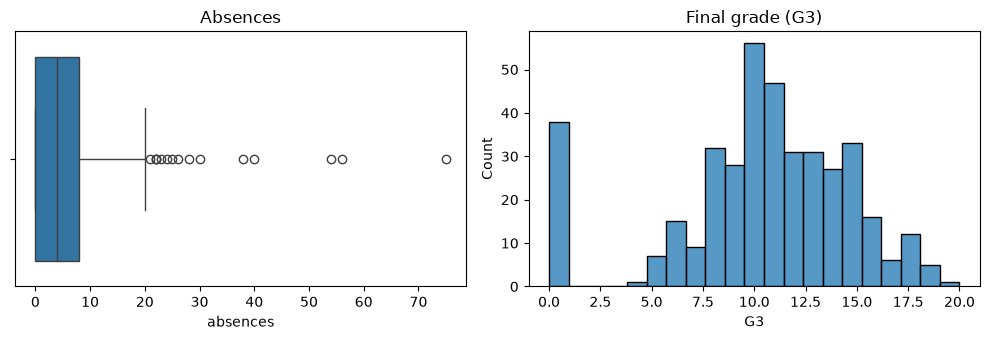

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=df_mat["absences"], ax=axes[0])
axes[0].set_title("Absences")
sns.histplot(df_mat["G3"], bins=21, ax=axes[1])
axes[1].set_title("Final grade (G3)")
plt.tight_layout()
plt.show()

absences has the most outliers, and G1/G2/G3 have a few
roughly 38 students have a final grade of 0

In [13]:
zero_g3 = df_mat[df_mat["G3"] == 0]
print("Students with G3 = 0:", len(zero_g3))
zero_g3[["G1", "G2", "G3", "absences"]].describe()

Students with G3 = 0: 38


,G1,G2,G3,absences
count,38.000000,38.000000,38.0,38.0
mean,7.526316,4.657895,0.0,0.0
std,1.811925,3.700083,0.0,0.0
min,4.000000,0.000000,0.0,0.0
25%,6.000000,0.000000,0.0,0.0
50%,7.000000,5.000000,0.0,0.0
75%,9.000000,8.000000,0.0,0.0
max,12.000000,10.000000,0.0,0.0


In [14]:
## Exploratory Data Analysis (EDA)
# Questions: do absences and study time relate to the final grade? Which features
# correlate most with G3? How do Math and Portuguese compare?


In [15]:
%load_ext autoreload
%autoreload 
# autoreload means that when you edit eda.py the notebook picks up the change without a restart.)
import matplotlib.pyplot as plt
from aislca.data.ingestion import load_processed_data
from aislca.analytics import eda

mat = load_processed_data("mat")
por = load_processed_data("por")
print(mat.shape, por.shape)

(395, 33) (649, 33)


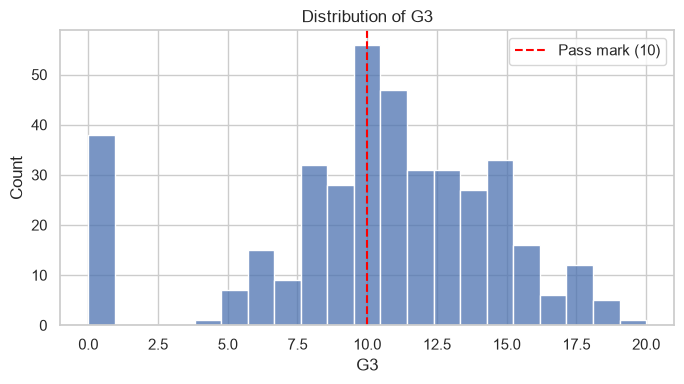

In [16]:
fig = eda.plot_grade_distribution(mat)
plt.show()

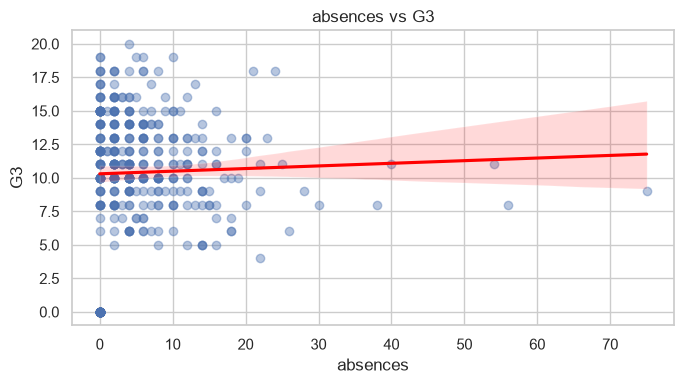

In [17]:
fig = eda.plot_scatter_vs_grade(mat, "absences")
plt.show()

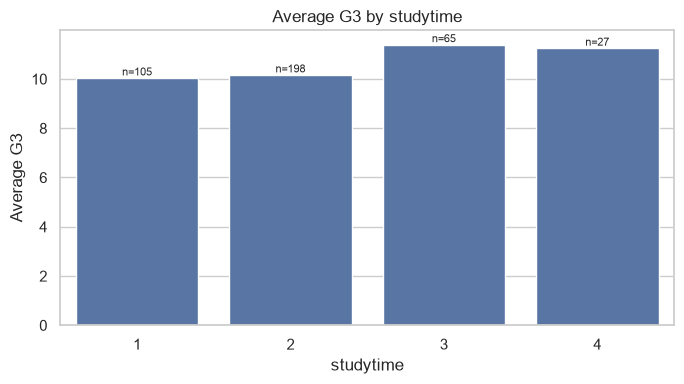

In [18]:
fig = eda.plot_mean_grade_by(mat, "studytime")
plt.show()

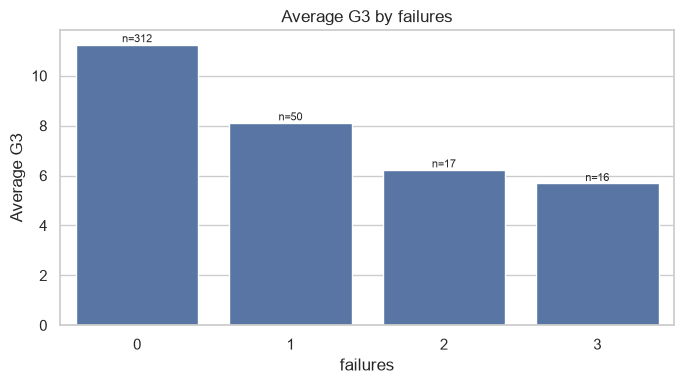

In [19]:
fig = eda.plot_mean_grade_by(mat, "failures")
plt.show()

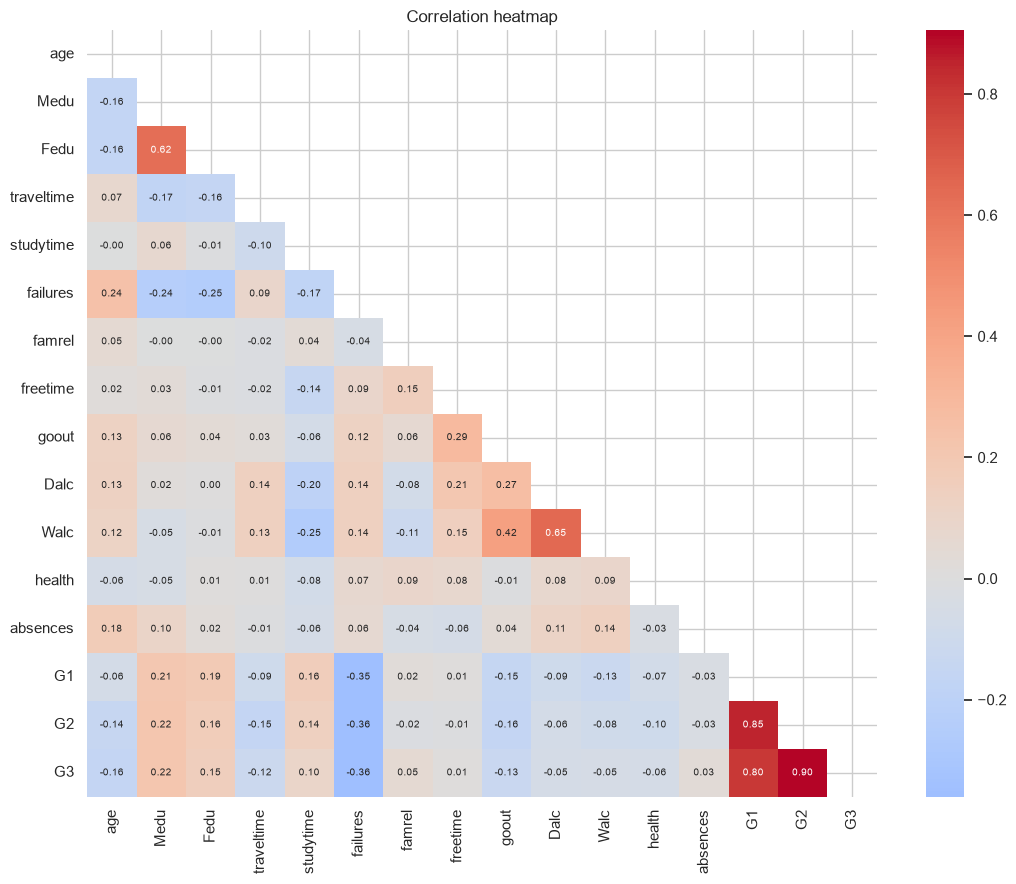

In [20]:
fig = eda.plot_correlation_heatmap(mat)
plt.show()

In [21]:
print(eda.top_correlations(mat, n=8))

corr_all = mat.select_dtypes("number").corr()["G3"]
corr_nonzero = mat[mat["G3"] > 0].select_dtypes("number").corr()["G3"]
comparison = pd.DataFrame(
    {"all_students": corr_all, "without_G3_zero": corr_nonzero}
).drop("G3").round(2)
comparison.reindex(comparison["all_students"].abs().sort_values(ascending=False).index)

G2            0.90
G1            0.80
failures     -0.36
Medu          0.22
age          -0.16
Fedu          0.15
goout        -0.13
traveltime   -0.12
Name: G3, dtype: float64


,all_students,without_G3_zero
G2,0.90,0.97
G1,0.80,0.89
failures,-0.36,-0.29
Medu,0.22,0.19
age,-0.16,-0.14
Fedu,0.15,0.16
goout,-0.13,-0.18
traveltime,-0.12,-0.10
studytime,0.10,0.13
health,-0.06,-0.08


               G1     G2     G3
Math        10.91  10.71  10.42
Portuguese  11.40  11.57  11.91


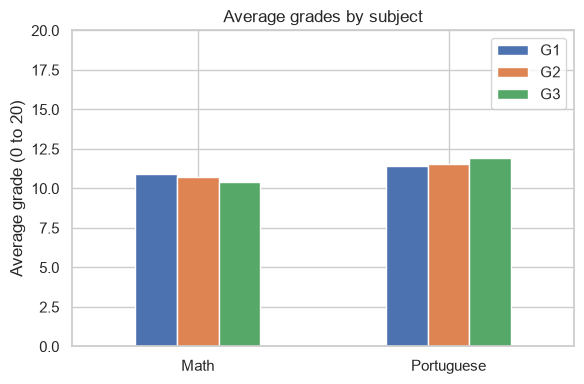

In [22]:
print(eda.subject_averages(mat, por))
fig = eda.plot_subject_averages(mat, por)
plt.show()

In [23]:
## Statistical analysis
# p < 0.05 = unlikely to be chance. It does NOT mean "big" or "causal".
# Always read the effect size (r, Cohen's d, Cramér's V) next to the p-value.


from aislca.analytics import stat_tests

corr_table = stat_tests.correlation_tests(mat)
corr_table


,feature,pearson_r,pearson_p,spearman_rho,spearman_p,significant
0,G2,0.905,0.0000,0.957,0.0000,True
1,G1,0.801,0.0000,0.878,0.0000,True
2,failures,-0.360,0.0000,-0.361,0.0000,True
3,Medu,0.217,0.0000,0.225,0.0000,True
4,age,-0.162,0.0013,-0.173,0.0005,True
5,Fedu,0.152,0.0024,0.170,0.0007,True
6,goout,-0.133,0.0082,-0.166,0.0009,True
7,traveltime,-0.117,0.0199,-0.121,0.0165,True
8,studytime,0.098,0.0521,0.105,0.0367,False
9,health,-0.061,0.2239,-0.048,0.3435,False


In [24]:
pd.Series(stat_tests.compare_two_groups(mat, "higher", "yes", "no"))

group_a               yes
n_a                   375
mean_a              10.61
group_b                no
n_b                    20
mean_b                6.8
mean_difference      3.81
welch_t_p          0.0024
mann_whitney_p     0.0006
cohens_d             0.84
dtype: object

In [25]:
pd.Series(stat_tests.compare_two_groups(mat, "internet", "yes", "no"))

group_a               yes
n_a                   329
mean_a              10.62
group_b                no
n_b                    66
mean_b               9.41
mean_difference      1.21
welch_t_p          0.0496
mann_whitney_p     0.0324
cohens_d             0.26
dtype: object

In [26]:
stat_tests.anova_by_group(mat, "studytime")

{'groups': 4,
 'f_statistic': np.float64(1.73),
 'anova_p': np.float64(0.1607),
 'kruskal_p': np.float64(0.0556)}

In [27]:
from aislca.data.ingestion import load_config

pass_mark = load_config()["target"]["pass_mark"]
mat_t = mat.assign(
    passed=(mat["G3"] >= pass_mark).astype(int),
    has_failures=(mat["failures"] > 0).astype(int),
)
result, table = stat_tests.chi_square_test(mat_t, "has_failures", "passed")
print(result)
table

{'chi2': np.float64(40.4), 'p_value': np.float64(0.0), 'degrees_of_freedom': 1, 'cramers_v': np.float64(0.32)}


passed,0,1
has_failures,,
0,78,234
1,52,31
